In [1]:
# === Imports ===
import numpy as np  # Array operations
import matplotlib.pyplot as plt  # Plotting
import pandas as pd  # Data handling
import pyp2options  # Custom library --> Calibrations
from astropy.coordinates import SkyCoord  # Astronomical coordinate handling
import astropy.units as u  # Physical units
import sys
import scipy.optimize as spopt  # Optimization algorithms
import scipy.stats as st
from scipy.stats import gaussian_kde

from matplotlib.backends.backend_pdf import PdfPages  # Save multiple figures into a PDF

In [31]:
# === Defined Parameters ===
field_name = 'MISHAPS_F1_DITH0'  # Field identifier
chip_id = 'N10'  # Chip identifier
magnitude_band = 'r'  # Band used for magnitude measurement
color_band_1 = 'r'  # First band for color (e.g. r-z)
color_band_2 = 'z'  # Second band for color
field_chip_label = f"{field_name}_{chip_id}"  # Combined label for file references

# === CMD Parameters ===
default_color_cut = 1.06
magnitude_cut = 17.3
color_range_min = 0.0
color_range_max = 2.0
msto_shift_value = 3.5  # Main Sequence Turn-Off shift

# === Color and Magnitude (Optional) Adjustments ===
# Adjust defaults for specific color combinations
if color_band_2 == "z" and color_band_1 == "r":
    default_color_cut = 0.46
    color_range_max = 1.0
    msto_shift_value = 3.0
    
# Enable interactive plots if enough command-line arguments are provided
interactive_mode = False
if len(sys.argv) >= 6:
    interactive_mode = True

# Optionally override color and magnitude cuts
if len(sys.argv) >= 7:
    default_color_cut = float(sys.argv[6])
    print("Color cut set to:", default_color_cut)

if len(sys.argv) >= 8:
    magnitude_cut = float(sys.argv[7])
    print("Magnitude cut set to:", magnitude_cut)

# print("Using magnitude and color bands:", magnitude_band, color_band_1, color_band_2)

In [32]:
# === Load Configuration from Options File ===
options = pyp2options.pip2options('/home/bernthold.17/SURP2025/fit_models/')

# Column indices for magnitudes (original indices from options)
mag_col_index = options['cmdm-' + magnitude_band] - 1
c1_col_index = options['cmdm-' + color_band_1] - 1
c2_col_index = options['cmdm-' + color_band_2] - 1

# Column indices for position
ra_col_index = 1
dec_col_index = 2

# === Quality Filters ===
# Column indices for quality flags (original indices from options)
qflag_mag = options['cmdq-' + magnitude_band] - 1
qflag_c1 = options['cmdq-' + color_band_1] - 1
qflag_c2 = options['cmdq-' + color_band_2] - 1

# === Output Reference Directory ===
reference_directory = '/home/bernthold.17/SURP2025/fit_models/'

# === Image Grid Dimensions ===
grid_cols = 4
grid_rows = 8
subimage_size = 2048.0 / grid_cols

/home/bernthold.17/SURP2025/fit_models/pyp2options.py:12: ParserWarning: Skipping line 65: expected 2 fields, saw 5
Skipping line 68: expected 2 fields, saw 5
Skipping line 71: expected 2 fields, saw 5
Skipping line 74: expected 2 fields, saw 5
Skipping line 80: expected 2 fields, saw 5
Skipping line 83: expected 2 fields, saw 5

  df = pd.read_csv(pipedir + '/pip2options.sh',sep='=',header=None,comment="#",on_bad_lines=on_bad_lines)


In [33]:
# === Red Clump Color Reference Function ===
def red_clump_color(l, b):
    """Returns the expected intrinsic color of the red clump stars given Galactic coordinates."""
    I_0 = 14.3955 - 0.0239 * l + 0.0122 * np.abs(b) # Dereddened I mag of the red clump (rc)
    I_mag = np.array([I_0, I_0 + 0.737, I_0 - 1.07]) # The I mag of the rc, red giant branch (rgbb),
                                                        # and asymptotic giant branch (agbb)
    dis_mod = I_mag - 14.3955 + 5.0 * np.log10(8178.0) - 5.0 # Distance modulus of bar peak density
    distance = 10**(0.2 * (dis_mod + 5.0)) # Distance from ... --> Figure it out
    V_mag = 1.060 + I_mag
    
    g_sdss = V_mag + 0.553 # g sdss filter (mag)
    r_sdss = V_mag - 0.327 # r sdss  filter (mag)
    i_sdss = V_mag - 0.600 # i sdss filter (mag)
    
    gmi_sdss = g_sdss - i_sdss # (g-i) sdss color
    
    rgbb_r_sdss = 1.060 + I_mag + 0.737 - 0.327 # r sdss filter of the red giant branch
    agbb_r_sdss = 1.060 + I_mag - 1.070 - 0.327 # r sdss filter of the asymptotic giant branch
    rgbb_gmi_sdss = 0.553 + 0.600 - 0.060 # (g-i) sdss color of the red giant branch
    agbb_gmi_sdss = 0.553 + 0.600 + 0.200 # (g-i) sdss color of the asymptotic giant branch
    
    # Transforms from SDSS to PanSTARRS
    for i in np.arange(0, 10):
        gpmgs = -0.01808 - 0.13595 * gmi_sdss + 0.01941 * gmi_sdss**2 - 0.00183 * gmi_sdss**3
        rpmrs = -0.01836 - 0.03577 * gmi_sdss + 0.02612 * gmi_sdss**2 - 0.00558 * gmi_sdss**3
        ipmis = 0.01170 - 0.00400 * gmi_sdss + 0.00066 * gmi_sdss**2 - 0.00058 * gmi_sdss**3
        g_ps1 = g_sdss + gpmgs #g panstarrs
        r_ps1 = r_sdss + rpmrs #r panstarrs
        i_ps1 = i_sdss + ipmis #i panstarrs
        gmi_ps1 = g_ps1 - i_ps1 #gmi panstarrs
        rmi_ps1 = r_ps1 - i_ps1 #rmi panstarrs
        imz_ps1 = 0.234625 + 0.211715 * (gmi_ps1 - 1.25) #i-z panstarrs
        rmz_ps1 = rmi_ps1 + imz_ps1 #r-z panstarrs
        z_ps1 = r_ps1 - rmz_ps1 #z panstarrs

    # Return the PanSTARRS magnitudes, distance, and distance modulus as a dictionary
    ret = {"clump-g":g_ps1[0], "clump-r":r_ps1[0], "clump-i":i_ps1[0], "clump-z":z_ps1[0],
           "rgbb-g":g_ps1[1], "rgbb-r":r_ps1[1], "rgbb-i":i_ps1[1], "rgbb-z":z_ps1[1],
           "agbb-g":g_ps1[2], "agbb-r":r_ps1[2], "agbb-i":i_ps1[2], "agbb-z":z_ps1[2],
           "distance":distance[0], "distance_modulus":dis_mod[0]}

    return ret

In [34]:
# === Load Photometric Catalog ===
catalog_path = "/home/bernthold.17/SURP2025/Data_Files/" + field_chip_label + ".cmd.calibrate_ps"

try:
    # Load as DataFrame first, which is best for type conversions
    photometric_catalog_df = pd.read_csv(catalog_path, delim_whitespace=True, comment='#', header=None)

    # List of column indices that MUST be numeric
    # Include all columns that will be used for calculations or selection
    numeric_cols_to_convert = list(set([
        mag_col_index, c1_col_index, c2_col_index,
        ra_col_index, dec_col_index,
        qflag_mag, qflag_c1, qflag_c2
    ]))
    numeric_cols_to_convert.sort() # Ensure consistent order

    # Apply pd.to_numeric to these specific columns in the DataFrame
    for col_idx in numeric_cols_to_convert:
        if col_idx < photometric_catalog_df.shape[1]:
            photometric_catalog_df.iloc[:, col_idx] = pd.to_numeric(
                photometric_catalog_df.iloc[:, col_idx], errors='coerce'
            )
        else:
            print(f"Warning: Column index {col_idx} for conversion is out of bounds for the loaded catalog. Skipping conversion for this column.")

    # Create a new NumPy array containing only these relevant columns,
    # and explicitly cast them to float. This ensures a homogeneous numeric array.
    try:
        photometric_catalog = photometric_catalog_df.iloc[:, numeric_cols_to_convert].values.astype(float)

        # Update your column indices to reflect their new positions in this smaller array
        # This is crucial for all subsequent indexing
        original_to_new_indices = {original_idx: new_idx for new_idx, original_idx in enumerate(numeric_cols_to_convert)}

        new_mag_col_index = original_to_new_indices[mag_col_index]
        new_c1_col_index = original_to_new_indices[c1_col_index]
        new_c2_col_index = original_to_new_indices[c2_col_index]
        new_ra_col_index = original_to_new_indices[ra_col_index]
        new_dec_col_index = original_to_new_indices[dec_col_index]
        new_qflag_mag = original_to_new_indices[qflag_mag]
        new_qflag_c1 = original_to_new_indices[qflag_c1]
        new_qflag_c2 = original_to_new_indices[qflag_c2]

    except ValueError as e:
        print(f"Critical Error: Could not convert selected columns to float during initial catalog processing: {e}")
        print("This usually means there are truly non-numeric values in the raw data that 'errors=coerce' couldn't handle, or a column index is wrong.")
        sys.exit(1)

    # Print dtypes of potentially problematic columns in photometric_catalog (using new indices)
    print(f"Dtype of mag_col_index ({new_mag_col_index}) in photometric_catalog: {photometric_catalog[:, new_mag_col_index].dtype}")
    print(f"Dtype of c1_col_index ({new_c1_col_index}) in photometric_catalog: {photometric_catalog[:, new_c1_col_index].dtype}")
    print(f"Dtype of c2_col_index ({new_c2_col_index}) in photometric_catalog: {photometric_catalog[:, new_c2_col_index].dtype}")
    print(f"Dtype of ra_col_index ({new_ra_col_index}) in photometric_catalog: {photometric_catalog[:, new_ra_col_index].dtype}")
    print(f"Dtype of dec_col_index ({new_dec_col_index}) in photometric_catalog: {photometric_catalog[:, new_dec_col_index].dtype}")
    print(f"Dtype of qflag_c1 ({new_qflag_c1}) in photometric_catalog: {photometric_catalog[:, new_qflag_c1].dtype}")


except Exception as error:
    print(f"Error loading catalog: {error}")
    sys.exit(1)
else:
    # Calculate min/max RA/Dec from the photometric_catalog (using new indices)
    ra_min = np.nanmin(photometric_catalog[:, new_ra_col_index])
    ra_max = np.nanmax(photometric_catalog[:, new_ra_col_index])
    dec_min = np.nanmin(photometric_catalog[:, new_dec_col_index])
    dec_max = np.nanmax(photometric_catalog[:, new_dec_col_index])

/tmp/slurmtmp.8778472/ipykernel_4006144/2312583496.py:6: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  photometric_catalog_df = pd.read_csv(catalog_path, delim_whitespace=True, comment='#', header=None)


Dtype of mag_col_index (4) in photometric_catalog: float64
Dtype of c1_col_index (4) in photometric_catalog: float64
Dtype of c2_col_index (2) in photometric_catalog: float64
Dtype of ra_col_index (0) in photometric_catalog: float64
Dtype of dec_col_index (1) in photometric_catalog: float64
Dtype of qflag_c1 (5) in photometric_catalog: float64


In [35]:
# === Apply Quality Filters to the Photometric Catalog ===
# It's crucial to filter out NaNs from the quality flags before using them for boolean indexing.
try:
    # Use new_qflag_c1 and new_qflag_c2
    q1_values_temp = photometric_catalog[:, new_qflag_c1].astype(int)
    q2_values_temp = photometric_catalog[:, new_qflag_c2].astype(int)
except ValueError as e:
    print(f"Error converting quality flags to integer: {e}. Check if quality flag columns contain non-integer/non-numeric values after pd.to_numeric.")
    sys.exit(1)

# Ensure finite and non-NaN quality flags
finite_qflags_mask = np.isfinite(q1_values_temp) & np.isfinite(q2_values_temp)
q1_values_temp = q1_values_temp[finite_qflags_mask]
q2_values_temp = q2_values_temp[finite_qflags_mask]
photometric_catalog = photometric_catalog[finite_qflags_mask] # Apply this mask to the whole catalog


valid_quality_mask = (q1_values_temp == 1) & (q2_values_temp == 1)

# Apply this quality mask
filtered_catalog_temp = photometric_catalog[valid_quality_mask]

# --- CRITICAL: Ensure filtered_catalog has numeric types for relevant columns ---
# This part is now cleaner as photometric_catalog should already be float
try:
    # Use new_c1_col_index, new_c2_col_index, new_mag_col_index
    c1_values = filtered_catalog_temp[:, new_c1_col_index]
    c2_values = filtered_catalog_temp[:, new_c2_col_index]
    mag_values = filtered_catalog_temp[:, new_mag_col_index]
except IndexError as e:
    print(f"Error accessing columns in filtered_catalog_temp: {e}. Check if new column indices are correct.")
    sys.exit(1)

# Apply finite mask to these arrays
finite_data_mask = (
    np.isfinite(c1_values) &
    np.isfinite(c2_values) &
    np.isfinite(mag_values)
)

# Apply this mask to the `filtered_catalog_temp` to get the rows that are clean
final_filtered_catalog = filtered_catalog_temp[finite_data_mask]

# And derive color_index and magnitude_values from the already clean and finite arrays
color_index = c1_values[finite_data_mask] - c2_values[finite_data_mask]
magnitude_values = mag_values[finite_data_mask]

# Print dtypes of color_index and magnitude_values here
print(f"Dtype of color_index after all filtering: {color_index.dtype}")
print(f"Dtype of magnitude_values after all filtering: {magnitude_values.dtype}")
print(f"Number of stars after quality and NaN filtering: {len(final_filtered_catalog)}")

Dtype of color_index after all filtering: float64
Dtype of magnitude_values after all filtering: float64
Number of stars after quality and NaN filtering: 34630


In [36]:
# === Optional Position Filtering ===
apply_position_cut = False # Set to True if you want to enable this. Your original code sets it to False
if apply_position_cut:
    # Use new_ra_col_index and new_dec_col_index
    try:
        ra_values_filtered = final_filtered_catalog[:, new_ra_col_index]
        dec_values_filtered = final_filtered_catalog[:, new_dec_col_index]
    except IndexError as e:
        print(f"Error accessing RA/Dec columns in final_filtered_catalog: {e}. Check if new column indices are correct.")
        sys.exit(1)

    within_bounds = (
        (ra_values_filtered > ra_min) & (ra_values_filtered < ra_max) &
        (dec_values_filtered > dec_min) & (dec_values_filtered < dec_max)
    )
    # Apply this final position filter to the catalog and the derived CMD arrays
    final_filtered_catalog = final_filtered_catalog[within_bounds]
    color_index = color_index[within_bounds] # Filter color_index as well
    magnitude_values = magnitude_values[within_bounds] # Filter magnitude_values as well
    print(f"Number of stars after position filtering: {len(final_filtered_catalog)}")

In [37]:
# === Galactic Coordinates ===
# Get the mean RA and Dec from the *final_filtered_catalog*
if len(final_filtered_catalog) > 0:
    ra = np.nanmean(final_filtered_catalog[:, new_ra_col_index])
    dec = np.nanmean(final_filtered_catalog[:, new_dec_col_index])
else:
    print("No stars remaining after filtering for Galactic coordinate calculation. Exiting.")
    sys.exit(1) # Exit if no data is left

# Get the l and b coordinates
coords = SkyCoord(ra,dec,frame = 'icrs',unit = u.deg)
l = coords.galactic.l.value
b = coords.galactic.b.value
# print("Galactic Coordinates:",l,b)
global rgbbmag0
global agbbmag0

# Estimate initial red clump guess
red_clump = red_clump_color(l, b)

clumpmag0 = red_clump["clump-" + magnitude_band]
rgbbmag0 = red_clump["rgbb-" + magnitude_band]
agbbmag0 = red_clump["agbb-" + magnitude_band]

print(f"Theoretical Red Clump Magnitude (clumpmag0): {clumpmag0:.3f}")

Theoretical Red Clump Magnitude (clumpmag0): 15.076


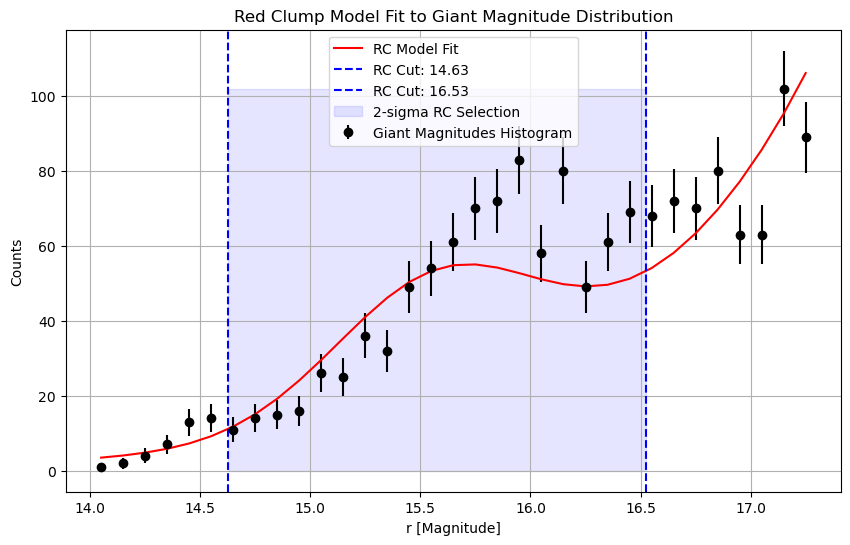

In [38]:
# === Red Clump Model (Quadratic + Gaussian) ===
def rcmodel(x, amplitude, slope, magnitude_rc, number_rc, sigma_rc):
    x = np.float64(x)
    A = amplitude*np.exp(slope*(x - magnitude_rc))
    B = number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-magnitude_rc)**2/sigma_rc**2)
    C = 0.201*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+rgbbmag0))**2/sigma_rc**2)
    D = 0.028*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+agbbmag0))**2/sigma_rc**2)
    return A + B + C + D 

# --- Visualization of the rcmodel fit ---
if len(hist_counts_m0) > 0 and not np.any(np.isnan(par_0)):
    plt.figure(figsize=(10, 6))
    plt.errorbar(bin_centers_m0, hist_counts_m0, yerr=np.sqrt(hist_counts_m0), fmt='ko', label='Giant Magnitudes Histogram')
    plt.plot(bin_centers_m0, rcmodel(bin_centers_m0, *par_0), 'r-', label='RC Model Fit')
    
    # Plot the 2-sigma cut boundaries
    if np.isfinite(par_0[2]) and np.isfinite(par_0[4]):
        lower_cut = par_0[2] - 2 * par_0[4]
        upper_cut = par_0[2] + 2 * par_0[4]
        plt.axvline(lower_cut, color='b', linestyle='--', label=f'RC Cut: {lower_cut:.2f}')
        plt.axvline(upper_cut, color='b', linestyle='--', label=f'RC Cut: {upper_cut:.2f}')
        plt.fill_betweenx([0, max(hist_counts_m0)], lower_cut, upper_cut, color='blue', alpha=0.1, label='2-sigma RC Selection')

    plt.xlabel(f"{magnitude_band} [Magnitude]")
    plt.ylabel("Counts")
    plt.title("Red Clump Model Fit to Giant Magnitude Distribution")
    plt.legend()
    plt.grid(True)
    plt.show()

In [39]:
# === Red Clump Gaussian ===
def cgauss(x, amplitude, mean, sigma):
    x = np.float64(x)
    return amplitude/(np.sqrt(2*np.pi*sigma**2))*np.exp(-0.5*(x-mean)**2/sigma**2)

In [70]:
# === Giant Star Selection ===
giant_selection_mask = (color_index > default_color_cut) & (magnitude_values < magnitude_cut)
giant_colors = color_index[giant_selection_mask]
giant_magnitudes = magnitude_values[giant_selection_mask]

print(f"Selected {len(giant_colors)} giant star candidates")

# For the magnitude distribution fit of the whole red giant branch
# Create a histogram of magnitudes
if len(giant_magnitudes) > 0:
    hist_counts_giant, bin_edges_giant = np.histogram(giant_magnitudes, range=(magnitude_cut - 4.0, magnitude_cut),
                                                      bins=40, density=False)
    bin_centers_giant = 0.5 * (bin_edges_giant[0:-1] + bin_edges_giant[1:])
else:
    print("No giant magnitudes for histogram. Skipping fit.")
    hist_counts_giant = np.array([])
    bin_centers_giant = np.array([])

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_0 = (hist_counts_giant > 0)
hist_counts_m0 = hist_counts_giant[mask_0]
bin_centers_m0 = bin_centers_giant[mask_0]

# --- Improved initial_guess_0 and added bounds for rcmodel fit ---
# [amplitude, slope, magnitude_rc, number_rc, sigma_rc]
if len(giant_magnitudes) > 0:
    # Try a more robust initial guess for amplitude (e.g., a small fraction of the mode)
    # And a more typical sigma for RC (0.15-0.25)
    # Estimate amplitude of the background (lowest counts at brightest end)
    initial_amp_guess = np.min(hist_counts_m0) if len(hist_counts_m0) > 0 else 5.0
    if initial_amp_guess == 0: initial_amp_guess = 5.0 # Avoid zero initial amplitude

    # Initial guess for number_rc, based on the peak of the histogram itself
    peak_mag_hist_idx = np.argmax(hist_counts_m0) if len(hist_counts_m0) > 0 else -1
    initial_number_rc_guess = hist_counts_m0[peak_mag_hist_idx] if peak_mag_hist_idx != -1 else 50.0
    if initial_number_rc_guess == 0: initial_number_rc_guess = 50.0 # Avoid zero number_rc

    initial_guess_0 = [
        initial_amp_guess,          # amplitude for background
        0.5,                        # slope for background
        clumpmag0,                  # magnitude_rc: Use theoretical red clump magnitude
        initial_number_rc_guess,    # number_rc: Use peak height as an estimate
        0.18                        # sigma_rc: More typical RC width (0.15 - 0.25)
    ]
    
    # Define bounds for the fit parameters
    # [amplitude, slope, magnitude_rc, number_rc, sigma_rc]
    # Allow magnitude_rc to vary more around clumpmag0, e.g., +/- 1.0 mag
    # Allow sigma_rc to vary in a reasonable range for RC width
    lower_bounds_0 = [0.0, -np.inf, clumpmag0 - 1.0, 0.0, 0.05] # magnitude_rc within 1 mag, min sigma 0.05
    upper_bounds_0 = [np.inf, np.inf, clumpmag0 + 1.0, np.inf, 0.35] # max sigma 0.35

    if len(hist_counts_m0) >= len(initial_guess_0): # Need at least as many data points as parameters
        try:
            par_0, cov_0 = spopt.curve_fit(rcmodel, bin_centers_m0, hist_counts_m0, p0=initial_guess_0,
                                           sigma=np.sqrt(hist_counts_m0), bounds=(lower_bounds_0, upper_bounds_0))
            amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_0
            print(f"rcmodel Fit Results:\nAmplitude = {par_0[0]:.2f}\n  Slope = {par_0[1]:.2f}\n Magnitude of red clump = {par_0[2]:.2f}\n  Number of red clump stars = {par_0[3]:.2f}\n  Sigma = {par_0[4]:.2f}")
            print(f"Fitted Red Clump Magnitude (par_0[2]): {par_0[2]:.3f}")
            print(f"Fitted Red Clump Sigma (par_0[4]): {par_0[4]:.3f}")
        except RuntimeError as e:
            print(f"rcmodel curve fitting failed: {e}")
            magnitude_giant = np.nan
            sigma_giant = np.nan
            par_0 = [np.nan, np.nan, np.nan, np.nan, np.nan]
    else:
        print("Not enough non-empty bins for rcmodel curve fitting. Skipping fit.")
        magnitude_giant = np.nan
        sigma_giant = np.nan
        par_0 = [np.nan, np.nan, np.nan, np.nan, np.nan]
else:
    print("No giant magnitudes for histogram. Skipping fit.")
    magnitude_giant = np.nan
    sigma_giant = np.nan
    par_0 = [np.nan, np.nan, np.nan, np.nan, np.nan]

Selected 1529 giant star candidates
rcmodel Fit Results:
Amplitude = 24.11
  Slope = 0.98
 Magnitude of red clump = 15.80
  Number of red clump stars = 43.26
  Sigma = 0.35
Fitted Red Clump Magnitude (par_0[2]): 15.796
Fitted Red Clump Sigma (par_0[4]): 0.350


In [71]:
# === Red Clump Star Selection ===
if not np.isfinite(magnitude_giant) or not np.isfinite(sigma_giant):
    print("Red clump model fit failed or resulted in non-finite parameters. Cannot select clump candidates.")
    clump_candidates = np.array([]) # Empty array if fit failed
    clump_colors = np.array([])
    clump_magnitudes = np.array([])
else:
    # Use magnitude_values (which is already correctly indexed and cleaned)
    rc_mag_mask = np.abs(magnitude_values - par_0[2]) < 2 * par_0[4]
    
    # Apply this mask to the final_filtered_catalog AND the already derived color_index/magnitude_values
    clump_candidates = final_filtered_catalog[rc_mag_mask]
    clump_colors = color_index[rc_mag_mask]
    clump_magnitudes = magnitude_values[rc_mag_mask]

# Ensure clump_colors and clump_magnitudes are finite as a final safety check
clump_colors = clump_colors[np.isfinite(clump_colors)]
clump_magnitudes = clump_magnitudes[np.isfinite(clump_magnitudes)]

print(f"Selected {len(clump_candidates)} red clump candidates")

# For the color distribution fit of stars in the red clump
# Create a histogram of colors
if len(clump_colors) > 0:
    hist_counts_clump, bin_edges_clump = np.histogram(clump_colors, range=(default_color_cut, default_color_cut + 1.5),
                                                      bins=60)
    bin_centers_clump = 0.5 * (bin_edges_clump[:-1] + bin_edges_clump[1:])
else:
    print("No clump colors for histogram. Skipping fit.")
    hist_counts_clump = np.array([])
    bin_centers_clump = np.array([])


# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_1 = (hist_counts_clump > 0)
hist_counts_m1 = hist_counts_clump[mask_1]
bin_centers_m1 = bin_centers_clump[mask_1]

# Initial guess for Gaussian parameters: amplitude, mean, sigma
if not np.isfinite(par_0[3]): # Check if number_giant from rcmodel fit is valid
    print("RC model number_giant is not finite. Cannot set initial guess for cgauss. Skipping fit.")
    amplitude, mean, sigma = np.nan, np.nan, np.nan # Set to NaN if fit fails
else:
    initial_guess_1 = [par_0[3] + 0.0, default_color_cut + 0.2, 0.2]
    
    # Ensure enough data for curve_fit
    if len(hist_counts_m1) >= len(initial_guess_1):
        try:
            par_1, cov_1 = spopt.curve_fit(cgauss, bin_centers_m1, hist_counts_m1, p0=initial_guess_1,
                                           sigma=np.sqrt(hist_counts_m1))
            amplitude, mean, sigma = par_1
            print(f"cgauss Model Fit Results:\nAmplitude = {par_1[0]:.2f}\n  Mean = {par_1[1]:.2f}\n Sigma = {par_1[2]:.2f}")
        except RuntimeError as e:
            print(f"cgauss curve fitting failed: {e}")
            amplitude, mean, sigma = np.nan, np.nan, np.nan
    else:
        print("Not enough non-empty bins for cgauss curve fitting. Skipping fit.")
        amplitude, mean, sigma = np.nan, np.nan, np.nan # Set to NaN if fit fails

Selected 927 red clump candidates
cgauss Model Fit Results:
Amplitude = 17.02
  Mean = 0.77
 Sigma = 0.09


In [72]:
# === Calculate the KDE for Giant and Clump Candidates ===
x_kde_giants = giant_colors # Already float and finite
y_kde_giants = giant_magnitudes # Already float and finite

x_kde_clumps = clump_colors # Already float and finite
y_kde_clumps = clump_magnitudes # Already float and finite


# Fit KDE for giants (1D magnitude)
if len(y_kde_giants) > 1: # KDE requires at least 2 points for 1D
    kde_giant_mag = gaussian_kde(y_kde_giants)
    x_giant_mag = np.linspace(np.min(y_kde_giants), np.max(y_kde_giants), 200)
    kde_giant_mag_vals = kde_giant_mag(x_giant_mag)
else:
    print("Not enough giant magnitudes for 1D KDE. Skipping.")
    kde_giant_mag_vals = np.array([])
    x_giant_mag = np.array([])

# Fit KDE for clumps (1D color)
if len(x_kde_clumps) > 1: # KDE requires at least 2 points for 1D
    kde_clump_col = gaussian_kde(x_kde_clumps)
    x_clump_col = np.linspace(np.min(x_kde_clumps), np.max(x_kde_clumps), 200)
    kde_clump_col_vals = kde_clump_col(x_clump_col)
else:
    print("Not enough clump colors for 1D KDE. Skipping.")
    kde_clump_col_vals = np.array([])
    x_clump_col = np.array([])

KDE max peak magnitude: 17.007
KDE min peak magnitude: 14.067


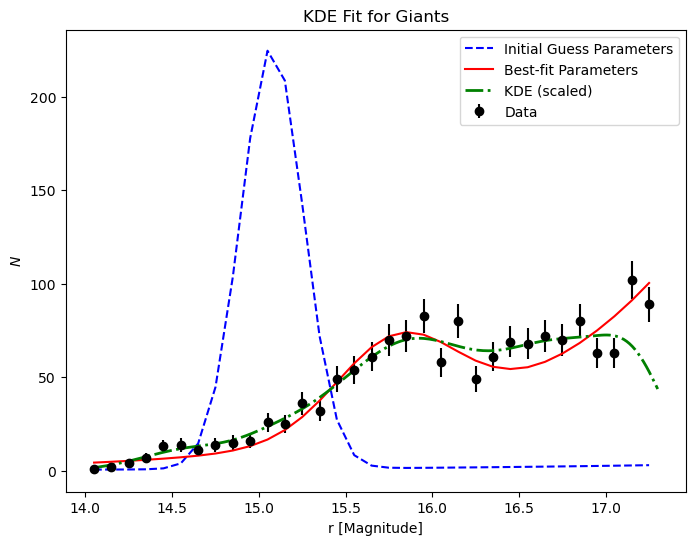

In [73]:
# === Plot the KDE for Giants (1D) ===
if len(kde_giant_mag_vals) > 0 and len(hist_counts_m0) > 0 and not np.any(np.isnan(par_0)):
    peak_max_mag_ind = np.argmax(kde_giant_mag_vals)
    peak_max_mag_kde = x_giant_mag[peak_max_mag_ind]
    print(f"KDE max peak magnitude: {peak_max_mag_kde:.3f}")

    if len(kde_giant_mag_vals) > 0:
        peak_min_mag_ind = np.argmin(kde_giant_mag_vals)
        peak_min_mag_kde = x_giant_mag[peak_min_mag_ind]
        print(f"KDE min peak magnitude: {peak_min_mag_kde:.3f}")

    plt.figure(figsize=(8,6))
    plt.tight_layout()
    plt.errorbar(bin_centers_m0, hist_counts_m0, yerr = np.sqrt(hist_counts_m0), fmt = 'ko', label = 'Data')

    # Re-plot initial guess and best-fit if they are valid
    if 'initial_guess_0' in locals() and not np.any(np.isnan(initial_guess_0)) and not np.any(np.isinf(initial_guess_0)):
        plt.plot(bin_centers_m0, rcmodel(bin_centers_m0, *initial_guess_0), 'b--', label = 'Initial Guess Parameters')
    if not np.any(np.isnan(par_0)) and not np.any(np.isinf(par_0)):
        plt.plot(bin_centers_m0, rcmodel(bin_centers_m0, *par_0), 'r-', label = 'Best-fit Parameters')

    # Scale KDE so it matches the historgrams vertical scale
    if len(y_kde_giants) > 0 and len(bin_edges_giant) > 1:
        bin_width_giant = bin_edges_giant[1] - bin_edges_giant[0]
        kde_giant_mag_vals_scaled = kde_giant_mag_vals * len(y_kde_giants) * bin_width_giant
        plt.plot(x_giant_mag, kde_giant_mag_vals_scaled, 'g-.', lw = 2, label='KDE (scaled)')

    plt.xlabel(f"{magnitude_band} [Magnitude]")
    plt.ylabel(r'$N$')
    plt.title('KDE Fit for Giants')

    plt.legend(loc='best')
    plt.show()
else:
    print("Skipping 1D KDE plot for Giants due to insufficient data or failed fit.")

KDE max peak color: 0.754
KDE min peak color: 1.450


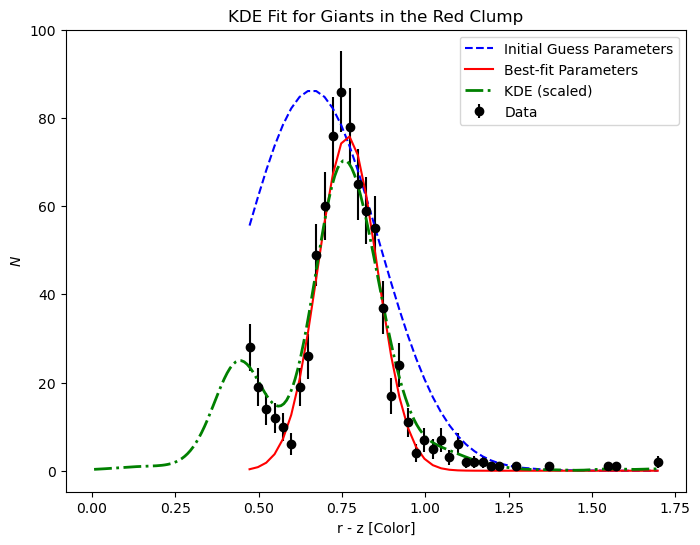

In [74]:
# === Plot the KDE for Red Clump Candidates (1D) ===
if len(kde_clump_col_vals) > 0 and len(hist_counts_m1) > 0 and not np.any(np.isnan(par_1)):
    peak_max_col_ind = np.argmax(kde_clump_col_vals)
    peak_max_col_kde = x_clump_col[peak_max_col_ind]
    print(f"KDE max peak color: {peak_max_col_kde:.3f}")

    if len(kde_clump_col_vals) > 0:
        peak_min_col_ind = np.argmin(kde_clump_col_vals)
        peak_min_col_kde = x_clump_col[peak_min_col_ind]
        print(f"KDE min peak color: {peak_min_col_kde:.3f}")

    plt.figure(figsize=(8,6))
    plt.tight_layout()
    plt.errorbar(bin_centers_m1, hist_counts_m1, yerr = np.sqrt(hist_counts_m1), fmt = 'ko', label = 'Data')

    # Re-plot initial guess and best-fit if they are valid
    if 'initial_guess_1' in locals() and not np.any(np.isnan(initial_guess_1)) and not np.any(np.isinf(initial_guess_1)):
        plt.plot(bin_centers_m1, cgauss(bin_centers_m1, *initial_guess_1), 'b--', label = 'Initial Guess Parameters')
    if not np.any(np.isnan(par_1)) and not np.any(np.isinf(par_1)):
        plt.plot(bin_centers_m1, cgauss(bin_centers_m1, *par_1), 'r-', label = 'Best-fit Parameters')

    # Scale KDE so it matches the historgrams vertical scale
    if len(x_kde_clumps) > 0 and len(bin_edges_clump) > 1:
        bin_width_clump = bin_edges_clump[1] - bin_edges_clump[0]
        kde_clump_col_vals_scaled = kde_clump_col_vals * len(x_kde_clumps) * bin_width_clump
        plt.plot(x_clump_col, kde_clump_col_vals_scaled, 'g-.', lw = 2, label='KDE (scaled)')

    plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
    plt.ylabel(r'$N$')
    plt.title('KDE Fit for Giants in the Red Clump')

    plt.legend(loc='best')
    plt.show()
else:
    print("Skipping 1D KDE plot for Red Clump Candidates due to insufficient data or failed fit.")

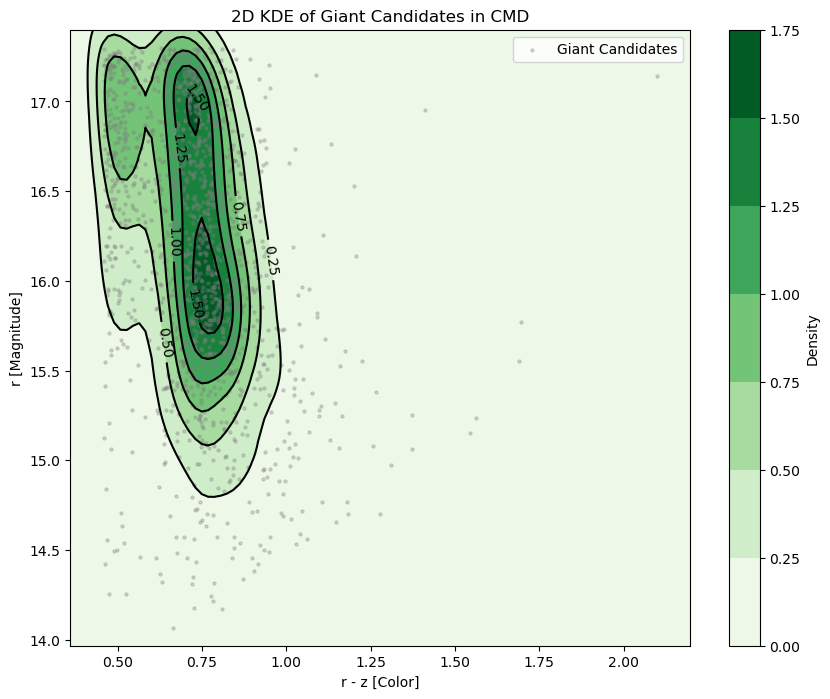

In [75]:
# --- 2D KDE for Giant Candidates ---

# Define x and y for the 2D KDE
x = giant_colors
y = giant_magnitudes

# Ensure that there is enough data for 2D KDE calculation (at least 2 points)
if len(x) < 2 or len(y) < 2:
    print("Not enough data points for 2D KDE after filtering. Skipping 2D KDE plot.")
else:
    # Define the plot limits based on your data and CMD parameters
    xmin, xmax = np.min(x) - 0.1, np.max(x) + 0.1
    ymin, ymax = np.min(y) - 0.1, np.max(y) + 0.1

    # Peform the kernel density estimate
    xx, yy = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
    positions = np.vstack([xx.ravel(), yy.ravel()])
    
    # Stack your x and y data for the KDE calculation
    values = np.vstack([x, y])
    
    # Create the KDE object
    kernel = st.gaussian_kde(values)
    
    # Evaluate the KDE on the grid
    f = np.reshape(kernel(positions).T, xx.shape)

    # Plotting the 2D KDE
    fig = plt.figure(figsize=(10, 8))
    ax = fig.gca()

    # Set plot limits
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    # Contourf plot (filled contours)
    cfset = ax.contourf(xx, yy, f, cmap='Greens')
    
    # You can also add the data points themselves on top of the KDE plot
    ax.scatter(x, y, s=5, color='gray', alpha=0.3, label='Giant Candidates')

    # Contour plot (lines only)
    cset = ax.contour(xx, yy, f, colors='k')
    
    # Label contours
    ax.clabel(cset, inline=1, fontsize=10)
    
    # Set labels and title
    ax.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
    ax.set_ylabel(f"{magnitude_band} [Magnitude]")
    ax.set_title('2D KDE of Giant Candidates in CMD')

    plt.colorbar(cfset, label='Density') # Add a color bar
    plt.legend()
    plt.show()

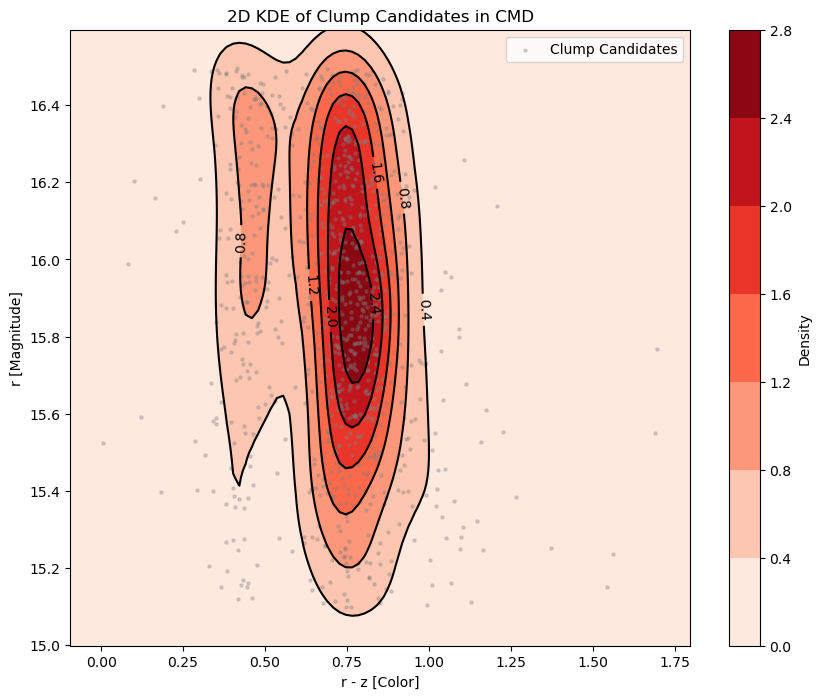

In [76]:
# --- 2D KDE for Red Clump Candidates ---

# Define x and y for the 2D KDE
x = clump_colors
y = clump_magnitudes

# Ensure that there is enough data for 2D KDE calculation (at least 2 points)
if len(x) < 2 or len(y) < 2:
    print("Not enough data points for 2D KDE after filtering. Skipping 2D KDE plot.")
else:
    # Define the plot limits based on your data and CMD parameters
    xmin, xmax = np.min(x) - 0.1, np.max(x) + 0.1
    ymin, ymax = np.min(y) - 0.1, np.max(y) + 0.1

    # Peform the kernel density estimate
    xx, yy = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
    positions = np.vstack([xx.ravel(), yy.ravel()])
    
    # Stack your x and y data for the KDE calculation
    values = np.vstack([x, y])
    
    # Create the KDE object
    kernel = st.gaussian_kde(values)
    
    # Evaluate the KDE on the grid
    f = np.reshape(kernel(positions).T, xx.shape)

    # Plotting the 2D KDE
    fig = plt.figure(figsize=(10, 8))
    ax = fig.gca()

    # Set plot limits
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    # Contourf plot (filled contours)
    cfset = ax.contourf(xx, yy, f, cmap='Reds')
    
    # You can also add the data points themselves on top of the KDE plot
    ax.scatter(x, y, s=5, color='gray', alpha=0.3, label='Clump Candidates')

    # Contour plot (lines only)
    cset = ax.contour(xx, yy, f, colors='k')
    
    # Label contours
    ax.clabel(cset, inline=1, fontsize=10)
    
    # Set labels and title
    ax.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
    ax.set_ylabel(f"{magnitude_band} [Magnitude]")
    ax.set_title('2D KDE of Clump Candidates in CMD')

    plt.colorbar(cfset, label='Density') # Add a color bar
    plt.legend()
    plt.show()